In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.chdir(r'C:\Users\ferna\OneDrive\Downloads\GitHub\ml_factorinv')

In [77]:
from data.data_load import *

In [78]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet

In [79]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [80]:
#help(Lasso)

## 5.1.1 Lasso

In [81]:
y_penalized = data_ml['R1M_Usd'].values # Dependent variable
X_penalized = data_ml[features_short].values # Predictors, use features_short for faster computing
alphas = np.logspace(-15, -2.5, 30) # here alpha is used for lambda in scikit-learn
lasso_res = {} # declaring the dict that will receive the model's result 

In [82]:
# Running as a POLS
for alpha in alphas:
    lasso = Lasso(alpha = alpha,)
    lasso.fit(X_penalized, y_penalized)
    lasso_res[alpha] = lasso.coef_

In [83]:
#print(lasso_res.keys())
#print(lasso_res.values())

In [84]:
df_lasso_res = pd.DataFrame.from_dict(lasso_res).T # transpose df, orifinal has keysas columns
df_lasso_res.columns = features_short # factor names
df_lasso_res

,Div_Yld,Eps,Mkt_Cap_12M_Usd,Mom_11M_Usd,Ocf,Pb,Vol1Y_Usd
1.000000e-15,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
2.697954e-15,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
7.278954e-15,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
1.963828e-14,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
5.298317e-14,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
1.429461e-13,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
3.856620e-13,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
1.040498e-12,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
2.807216e-12,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730
7.573739e-12,-0.000777,-0.011348,-0.022699,-0.010530,0.015938,-0.009440,0.007730


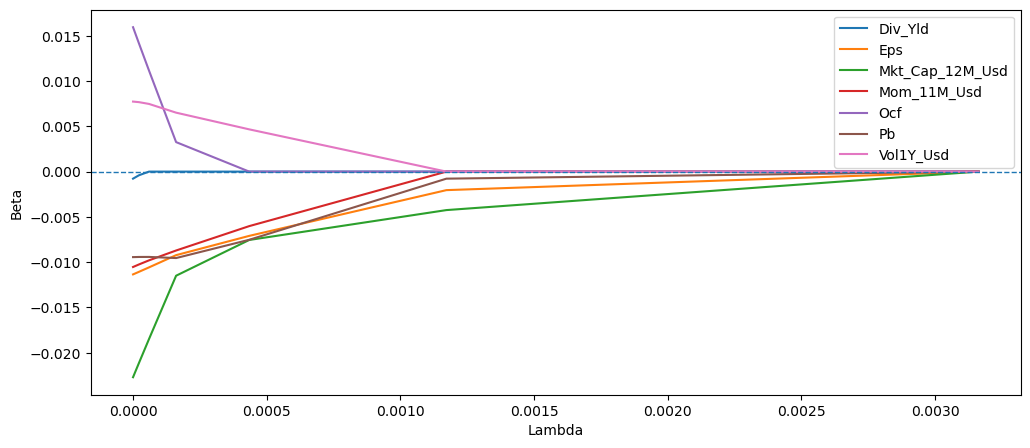

In [85]:
# Regularization Path
ax = df_lasso_res.plot(xlabel="Lambda", ylabel="Beta", figsize=(12, 5))
ax.axhline(0, linestyle="--", linewidth=1)

## 5.1.2 Ridge

In [86]:
n_alphas  = 100 # training is simpler. So I have estimated more models.
alphas    = np.logspace(-100,5,n_alphas)
ridge_res = {}

In [87]:
for alpha in alphas:
    ridge = Ridge(alpha = alpha)
    ridge.fit(X_penalized, y_penalized)
    ridge_res[alpha] = ridge.coef_

In [88]:
df_ridge_res = pd.DataFrame.from_dict(ridge_res).T
df_ridge_res.columns = features_short
df_ridge_res.head()

,Div_Yld,Eps,Mkt_Cap_12M_Usd,Mom_11M_Usd,Ocf,Pb,Vol1Y_Usd
1.000000e-100,-0.000777,-0.011348,-0.022699,-0.01053,0.015938,-0.00944,0.00773
1.149757e-99,-0.000777,-0.011348,-0.022699,-0.01053,0.015938,-0.00944,0.00773
1.321941e-98,-0.000777,-0.011348,-0.022699,-0.01053,0.015938,-0.00944,0.00773
1.519911e-97,-0.000777,-0.011348,-0.022699,-0.01053,0.015938,-0.00944,0.00773
1.747528e-96,-0.000777,-0.011348,-0.022699,-0.01053,0.015938,-0.00944,0.00773


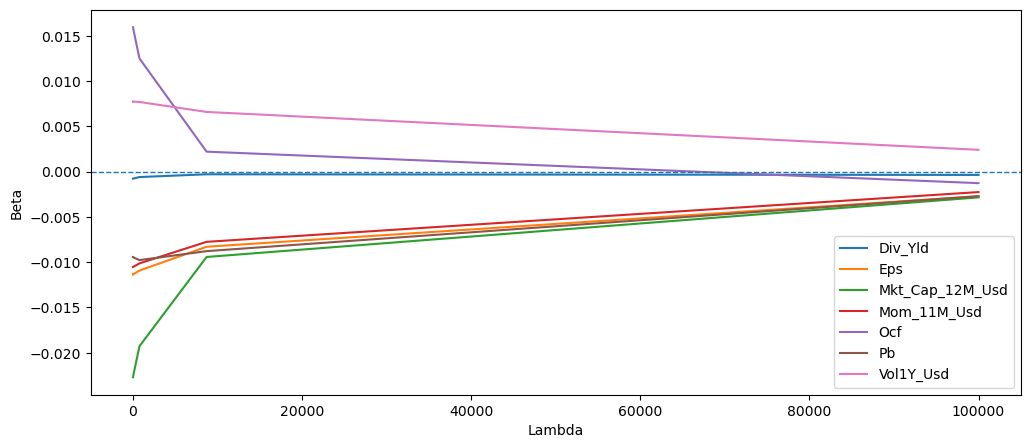

In [89]:
# Regularization Path
ax = df_ridge_res.plot(xlabel="Lambda",ylabel="Beta",figsize=(12, 5))
ax.axhline(0, linestyle="--", linewidth=1)

## 5.2 Sparse hedge portfolios + ElasticNet

We want to compare 3 strategies: 
1. Equally weighted (EW) benchmark of all stocks
2. Classical global minimum variance portfolio (GMV)
3. Sparse-hedging approach to minimum variance - Elastic Net + MSE hyperparameter optimization.
4. Sparse-hedging approach to minimum variance - Elastic Net + Sharpe hyperparameter optimization.

Obs:
* No return estimation for minimum variance portfolios (We set $\mu = 1$).
* One may additionally combine predicted returns from penalized regressions + penalized covariance matrix.
* We perform backtesting on all strategies.

In [90]:
t_oos   = returns.index[returns.index > sep_date].values # OOS dates
Tt      = len(t_oos)
nb_port = 4 # number of strategies

In [91]:
port_weights = {} # portf. weights in dict
port_returns = {} # portf. returns in dict

In [92]:
returns.head(2)

stock_id,1,3,4,7,9,11,12,16,17,18,...,1199,1200,1201,1202,1203,1204,1208,1209,1210,1212
date,,,,,,,,,,,,,,,,,,,,,
2000-01-31,-0.036,0.077,-0.016,-0.009,0.032,0.144,-0.11,-0.191,-0.103,0.098,...,-0.509,0.039,-0.011,-0.019,0.168,0.080,-0.372,-0.560,-0.006,-0.186
2000-02-29,0.263,-0.024,0.000,0.027,0.076,0.258,0.11,0.197,-0.053,-0.001,...,-0.147,0.017,-0.148,0.118,0.177,0.161,0.143,-0.102,-0.057,0.104


In [93]:
# Fucntion to get weights for sparse hedge
def weights_sparsehedge(returns, alpha, Lambda):
    weights = []
    lr_en   = ElasticNet(alpha=alpha, l1_ratio= Lambda)
    for col in returns.columns: # returns: R1M_USD for stocks available in all dates
        y = returns[col].values
        X = returns.drop(col,axis=1).values
        lr_en.fit(X,y)
        err = y - lr_en.predict(X)
        w = (1-np.sum(lr_en.coef_))/np.var(err)
        weights.append(w)
    return weights/np.sum(weights)   

In [94]:
# Function to get weight for any of the strategies
def weights_multi(returns, j, alpha, Lambda, delta = 1e-2):
    N = returns.shape[1]
    if j == 0: # EW
        return np.repeat(1/N, N)
    elif j == 1: # GMV
        sigma = np.cov(returns.T) + delta * np.identity(N) # Ledoit Wolf 2004, shrinkage term delta since K > N
        w     = np.matmul(np.linalg.inv(sigma), np.repeat(1,N)) 
        return w/ np.sum(w)
    elif j >= 2: # Sparse hedge strategies, there are 3
        return weights_sparsehedge(returns, alpha, Lambda)

In [95]:
# Optimize Elastic Net hyperparameters (alpha and l1_ratio) using Optuna.
# Two alternative objectives evaluated on the validation sample:
# (1) Minimize prediction error (MSE) across individual asset regressions.
# (2) Maximize the Sharpe ratio of the resulting portfolio.

import optuna

def optimize_sparsehedge(returns_train, returns_val, objective_type='sharpe', n_trials=100):

    def objective(trial):
        alpha = trial.suggest_float('alpha', 1e-10, 10, log=True)
        Lambda = trial.suggest_float('Lambda', 0.0, 1.0)

        if objective_type == 'mse':
            errors = []
            for col in returns_train.columns:
                X_train = returns_train.drop(columns=col)
                X_val   = returns_val.drop(columns=col)

                model = ElasticNet(alpha=alpha, l1_ratio=Lambda)
                model.fit(X_train, returns_train[col])

                errors.extend((returns_val[col] - model.predict(X_val))**2)

            return np.mean(errors)

        elif objective_type == 'sharpe':
            weights = np.asarray(weights_sparsehedge(returns_train, alpha, Lambda))
            portfolio_returns = returns_val.to_numpy() @ weights

            std = np.std(portfolio_returns, ddof=1)
            return np.mean(portfolio_returns) / std if std > 1e-12 else -1e10

        else:
            raise ValueError("objective_type must be 'mse' or 'sharpe'")

    if objective_type not in ('mse', 'sharpe'):
        raise ValueError("objective_type must be 'mse' or 'sharpe'")

    direction = 'minimize' if objective_type == 'mse' else 'maximize'

    study = optuna.create_study(direction=direction)
    study.optimize(objective, n_trials=n_trials)

    return study


In [98]:
# MSE + Sharpe hyperparameter optimization

# data
temp_data_train = returns.iloc[returns.index <= sep_val,:]
temp_data_val   = returns.iloc[(returns.index > sep_val) & (returns.index <= sep_test),:]

# MSE
study_mse = optimize_sparsehedge(temp_data_train, temp_data_val, objective_type='mse', n_trials=25)

# Sharpe
study_sharpe = optimize_sparsehedge(temp_data_train, temp_data_val, objective_type='sharpe', n_trials=25)

[I 2026-10-14 14:08:18,595] A new study created in memory with name: no-name-1072eeaf-cb63-48eb-8db7-273a0be7737a
[I 2026-10-14 14:08:27,308] Trial 0 finished with value: 0.029139163306522563 and parameters: {'alpha': 6.944750393975837e-09, 'Lambda': 0.14517279007615225}. Best is trial 0 with value: 0.029139163306522563.
[I 2026-10-14 14:09:04,868] Trial 1 finished with value: 0.038096253071895715 and parameters: {'alpha': 0.00011586191526779181, 'Lambda': 0.541190952209451}. Best is trial 0 with value: 0.029139163306522563.
[I 2026-10-14 14:09:13,783] Trial 2 finished with value: 0.021947108816380678 and parameters: {'alpha': 0.016690399872289208, 'Lambda': 0.46886447809979626}. Best is trial 2 with value: 0.021947108816380678.
[I 2026-10-14 14:09:22,631] Trial 3 finished with value: 0.01544907502075452 and parameters: {'alpha': 2.8651507553522944, 'Lambda': 0.18443541404416486}. Best is trial 3 with value: 0.01544907502075452.
[I 2026-10-14 14:10:11,984] Trial 4 finished with value: 

In [101]:
print(study_mse.best_params)
print(study_sharpe.best_params)

{'alpha': 0.2412251436564427, 'Lambda': 0.012049825842927152}
{'alpha': 0.11907519356751732, 'Lambda': 0.490114380757938}


In [102]:
study_mse.best_params['alpha']

0.2412251436564427

In [110]:
for m, month in np.ndenumerate(t_oos):  # Loop over monthly rebalancing dates

    temp_data = returns.loc[returns.index < month]
    realised_returns = returns.loc[returns.index == month].values

    weights_temp = {}
    returns_temp = {}

    for j in range(nb_port):

        if j in (0, 1):
            wgts = weights_multi(temp_data, j, alpha = study_mse.best_params['alpha'], Lambda=study_mse.best_params['Lambda'])
        elif j == 2:
            wgts = weights_multi(temp_data, j, alpha = study_mse.best_params['alpha'], Lambda=study_mse.best_params['Lambda'])
        elif j == 3:
            wgts = weights_multi(temp_data, j, alpha = study_sharpe.best_params['alpha'], Lambda=study_sharpe.best_params['Lambda'])
        else:
            raise ValueError(f'Strategy {j} not specified')

        # Out-of-sample portfolio return
        rets = np.sum(wgts * realised_returns)

        weights_temp[j] = wgts
        returns_temp[j] = rets

    # Dict of dicts
    port_weights[month] = weights_temp # only saves, does not use. Each month has a dict of {'strategy': wgts}
    port_returns[month] = returns_temp # Each month has a dict of {'strategy': returns}

    if m[0] % 10 == 0:
        print(m[0])

0
10
20
30
40
50


In [120]:
# Each item has a key of date and values of dicts
for k, v in port_returns.items():
    print(k, '\n', v)
    break

2014-01-31T00:00:00.000000000 
 {0: np.float64(0.04037578814627995), 1: np.float64(0.023470667838931116), 2: np.float64(0.03322404332037625), 3: np.float64(0.03363845575432857)}


In [126]:
# Create a dataframe for v
# Asociate each dataframe with a date k
# Concatenate all dataframes within axis 0
port_returns_final = pd.concat(
    {k: pd.DataFrame.from_dict(v, orient='index')
     for k, v in port_returns.items()},
    axis=0
).reset_index()

In [128]:
port_returns_final.head()

,level_0,level_1,0
0,2014-01-31,0,0.040376
1,2014-01-31,1,0.023471
2,2014-01-31,2,0.033224
3,2014-01-31,3,0.033638
4,2014-02-28,0,0.010201


In [129]:
colnames = ['date','strategy','return'] # Colnames
port_returns_final.columns = colnames # Colnames
strategies_name = {0:'EW',1:'MV',2:'Sparse_mse', 3:'Sparse_sharpe'}
port_returns_final['strategy'] = port_returns_final['strategy'].replace(strategies_name)
pd.DataFrame(port_returns_final.groupby('strategy')['return'].std()).T # Portfolio volatilities (monthly scale)

strategy,EW,MV,Sparse_mse,Sparse_sharpe
return,0.041804,0.033504,0.034385,0.034741


In [ ]:
list(port_returns.items())[0][0]; list(port_returns.items())[0][1]

<Axes: title={'center': 'Cumulative Portfolio Returns'}, xlabel='Date', ylabel='Cumulative Wealth'>

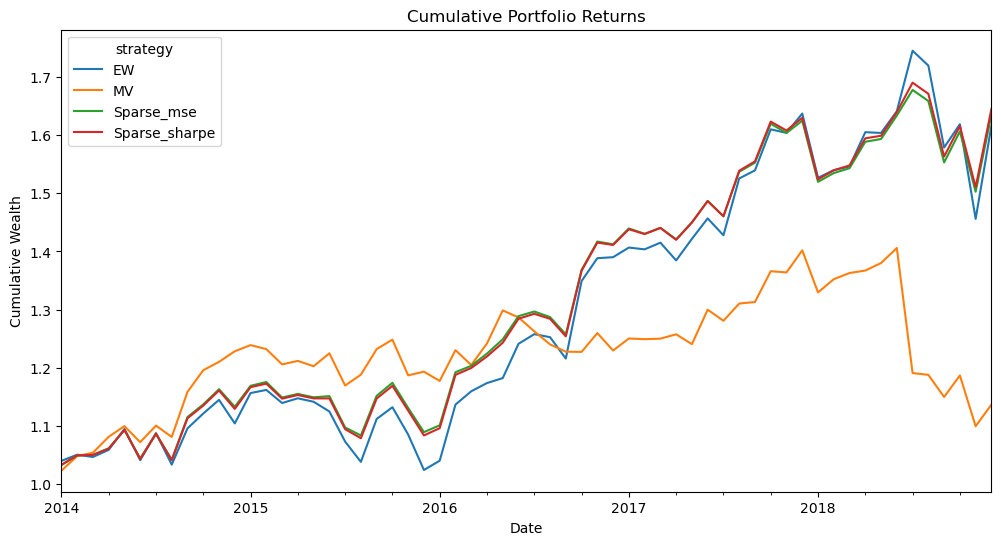

In [131]:
temp = port_returns_final.pivot(columns='strategy', index = 'date', values = 'return')
(1 + temp).cumprod().plot(
    figsize=(12, 6),
    title='Cumulative Portfolio Returns',
    xlabel='Date',
    ylabel='Cumulative Wealth'
)

## 5.3 Predictive Regressions
* Predict returns using penalized regressions.
* In `MLF5_mine.ipynb`, I optimize the hyperparameters using a rolling-window approach.

In [176]:
y_penalized_train = data_ml.loc[idx_train,:]['R1M_Usd'].values 
X_penalized_train = data_ml.loc[idx_train,:][features_short].values  

model = ElasticNet(alpha=study_sharpe.best_params['alpha'], l1_ratio=study_sharpe.best_params['Lambda']) 

fir_pen_pred = model.fit(X_penalized_train,y_penalized_train) # fitting the model

In [177]:
y_penalized_test = data_ml.loc[idx_test,:]['R1M_Usd'].values # Dependent variable
X_penalized_test = data_ml.loc[idx_test,:][features_short].values # Predictors
mse = np.mean((fir_pen_pred.predict(X_penalized_test) - y_penalized_test)**2)
print(f'MSE: {mse}')

MSE: 0.03698897303232217


In [178]:
hitratio = np.mean(fir_pen_pred.predict(X_penalized_test) * y_penalized_test > 0)
print(f'Hit Ratio: {hitratio}')

Hit Ratio: 0.5460346399270738


In [179]:
# Coefs are all 0 in our optimization. Predicts intercept only!
print(study_sharpe.best_params)
print(model.get_params())
print(model.coef_)
print(np.std(fir_pen_pred.predict(X_penalized_test)))

{'alpha': 0.11907519356751732, 'Lambda': 0.490114380757938}
{'alpha': 0.11907519356751732, 'copy_X': True, 'fit_intercept': True, 'l1_ratio': 0.490114380757938, 'max_iter': 1000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
[-0. -0. -0. -0. -0. -0.  0.]
5.204170427930421e-18


In [181]:
# Why optimization occurs when all coefs are 0?
# 1) Short list of coefficients. Maybe these coefficients of features_short do not have predictive power.
# 2) Need to adjust optuna and feature scaling: low hyperparameter values zero out all coeficients.